## Implementing algorithm 1 from the paper. 
Computing omega points for the 3vs1 case
including the functions to check if points are in a good position 


In [7]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan     
import itertools

import numpy.linalg

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog

import sys 
sys.path.append('../Code/')
import modules as mod
import examples as ex
import plot as ourplot
import csv

import omega_pts as omega
# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Note to selves: both 2:2 and 3:1 still need that we remove omega pts if they are already crit pts

Also note to self: needed to say CritPts[a].coords instead of CritPts[a] here for checking 4 distinct to actually work. Should we update elsewhere? check.

## Examples from the paper

### Example 2.13, figure 3

$M = [0,7)\times [0,8) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,8)$

In [8]:
CritPts = ex.example_2_13()
CritPts

[(parent module of (0.0, 0.0) is 0),
 (parent module of (7.0, 0.0) is 0),
 (parent module of (0.0, 4.0) is 0),
 (parent module of (7.0, 4.0) is 0),
 (parent module of (0.0, 8.0) is 0),
 (parent module of (0.0, 11.0) is 0),
 (parent module of (0.0, 0.0) is 1),
 (parent module of (7.0, 0.0) is 1),
 (parent module of (0.0, 4.0) is 1),
 (parent module of (7.0, 4.0) is 1),
 (parent module of (0.0, 8.0) is 1),
 (parent module of (0.0, 11.0) is 1)]

**********
Computed 1794 points (with duplicates)
Without duplicates 59


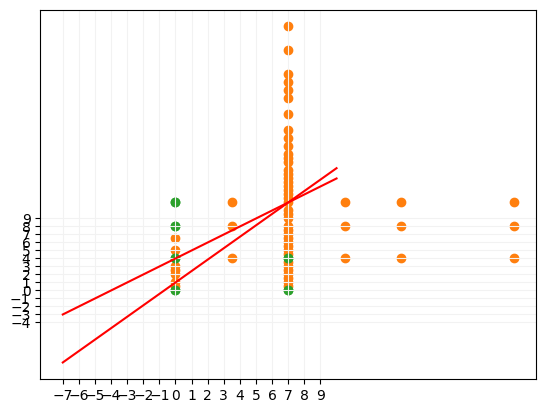

In [9]:
CritPts = ex.example_2_13()
name = "Example_2_13"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [10]:
CritPts = ex.example_2_13()
CritPts
name = "Example_2_13"
Omega_pts = omega.output_alg_2_2_paired(CritPts, name)

beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 4.0), (0.0, 4.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 4.0), (0.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 4.0), (7.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 4.0), (0.0, 4.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (7.0, 4.0), (7.0, 4.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (7.0, 4.0), (0.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (7.0, 4.0), (7.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (7.0, 4.0), (7.0, 4.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 8.0), (0.0, 8.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 8.0), (0.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 8.0), (7.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 8.0), (0.0, 8.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 11.0), (0.0, 11.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 11.0), (0.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 11.0), (7.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 11.0), (0.0, 11.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 0.0), (0.0, 0.0)]
beepbeep

### Example 2.11

$M = [0,7)\times [0,7) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,7)$

**********
Computed 1804 points (with duplicates)
Without duplicates 54


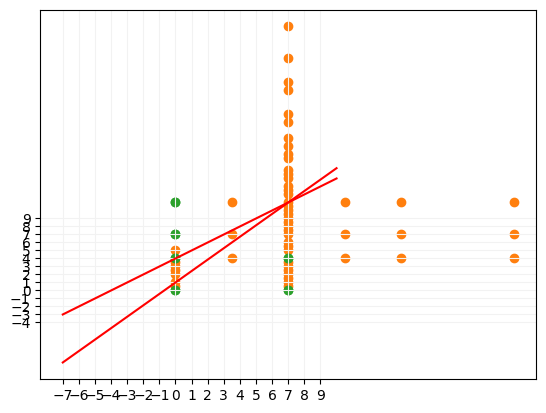

In [11]:
CritPts = ex.example_2_11()
name = "Example_2_11"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [12]:
CritPts = ex.example_2_11()
name = "Example_2_11"
Omega_pts = omega.output_alg_2_2_paired(CritPts, name)

beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 4.0), (0.0, 4.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 4.0), (0.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 4.0), (7.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 4.0), (0.0, 4.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (7.0, 4.0), (7.0, 4.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (7.0, 4.0), (0.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (7.0, 4.0), (7.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (7.0, 4.0), (7.0, 4.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 7.0), (0.0, 7.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 7.0), (0.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 7.0), (7.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 7.0), (0.0, 7.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 11.0), (0.0, 11.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 11.0), (0.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 11.0), (7.0, 0.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 11.0), (0.0, 11.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 0.0), (0.0, 0.0)]
beepbeep

### Example 1
$M=[0,7]\times[0,8]$ and $N=[1,8]\times[1,9]$

**********
Computed 132 points (with duplicates)
Without duplicates 39


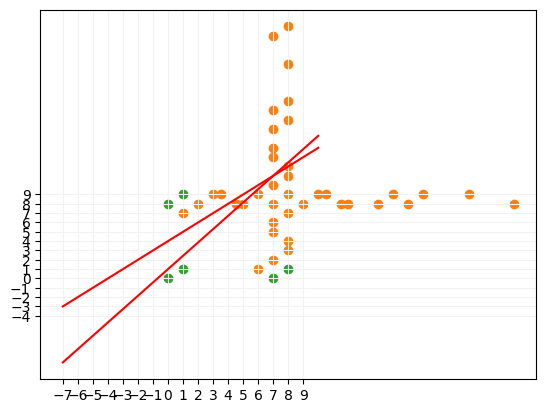

In [13]:
CritPts = ex.example_1()
name = "Example_1"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [14]:
CritPts = ex.example_1()
name = "Example_1"
Omega_pts = omega.output_alg_2_2_paired(CritPts, name)

beepbeep [(0.0, 0.0), (7.0, 0.0), (0.0, 8.0), (0.0, 8.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (1.0, 1.0), (1.0, 1.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (8.0, 1.0), (8.0, 1.0)]
beepbeep [(0.0, 0.0), (7.0, 0.0), (1.0, 9.0), (1.0, 9.0)]
beepbeep [(0.0, 0.0), (0.0, 8.0), (1.0, 1.0), (1.0, 1.0)]
beepbeep [(0.0, 0.0), (0.0, 8.0), (8.0, 1.0), (8.0, 1.0)]
beepbeep [(0.0, 0.0), (0.0, 8.0), (1.0, 9.0), (1.0, 9.0)]
beepbeep [(0.0, 0.0), (1.0, 1.0), (8.0, 1.0), (8.0, 1.0)]
beepbeep [(0.0, 0.0), (1.0, 1.0), (1.0, 9.0), (1.0, 9.0)]
beepbeep [(0.0, 0.0), (8.0, 1.0), (1.0, 9.0), (1.0, 9.0)]
beepbeep [(7.0, 0.0), (0.0, 8.0), (1.0, 1.0), (1.0, 1.0)]
beepbeep [(7.0, 0.0), (0.0, 8.0), (8.0, 1.0), (8.0, 1.0)]
beepbeep [(7.0, 0.0), (0.0, 8.0), (1.0, 9.0), (1.0, 9.0)]
beepbeep [(7.0, 0.0), (1.0, 1.0), (8.0, 1.0), (8.0, 1.0)]
beepbeep [(7.0, 0.0), (1.0, 1.0), (1.0, 9.0), (1.0, 9.0)]
beepbeep [(7.0, 0.0), (8.0, 1.0), (1.0, 9.0), (1.0, 9.0)]
beepbeep [(0.0, 8.0), (1.0, 1.0), (8.0, 1.0), (8.0, 1.0)]
beepbeep [(0.0

### Example 2 
$M=[0,4]\times[0,4]$ and $N=[1,3]\times[0,4]$

Should have $(1,1),(2,2),(3,3)$ as $\Omega$-pts

**********
Computed 91 points (with duplicates)
Without duplicates 17


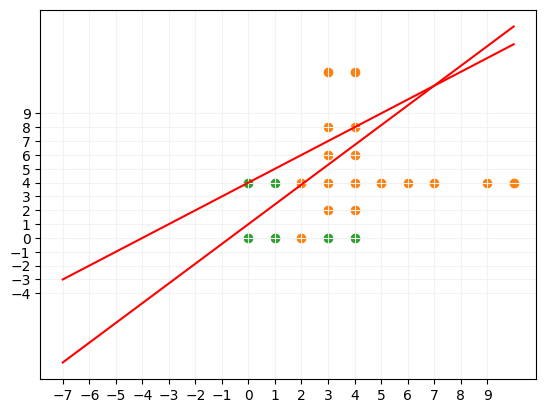

In [15]:
CritPts = ex.example_2()
name = "Example_2"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)


In [16]:
CritPts = ex.example_2()
Omega_pts = omega.output_alg_2_2_paired(CritPts, name = "Example_2")

beepbeep [(0.0, 0.0), (4.0, 0.0), (0.0, 4.0), (0.0, 4.0)]
beepbeep [(0.0, 0.0), (4.0, 0.0), (1.0, 0.0), (1.0, 0.0)]
beepbeep [(0.0, 0.0), (4.0, 0.0), (3.0, 0.0), (3.0, 0.0)]
beepbeep [(0.0, 0.0), (4.0, 0.0), (1.0, 4.0), (1.0, 4.0)]
beepbeep [(0.0, 0.0), (0.0, 4.0), (1.0, 0.0), (1.0, 0.0)]
beepbeep [(0.0, 0.0), (0.0, 4.0), (3.0, 0.0), (3.0, 0.0)]
beepbeep [(0.0, 0.0), (0.0, 4.0), (1.0, 4.0), (1.0, 4.0)]
beepbeep [(0.0, 0.0), (1.0, 0.0), (3.0, 0.0), (3.0, 0.0)]
beepbeep [(0.0, 0.0), (1.0, 0.0), (1.0, 4.0), (1.0, 4.0)]
beepbeep [(0.0, 0.0), (3.0, 0.0), (1.0, 4.0), (1.0, 4.0)]
beepbeep [(4.0, 0.0), (0.0, 4.0), (1.0, 0.0), (1.0, 0.0)]
beepbeep [(4.0, 0.0), (0.0, 4.0), (3.0, 0.0), (3.0, 0.0)]
beepbeep [(4.0, 0.0), (0.0, 4.0), (1.0, 4.0), (1.0, 4.0)]
beepbeep [(4.0, 0.0), (1.0, 0.0), (3.0, 0.0), (3.0, 0.0)]
beepbeep [(4.0, 0.0), (1.0, 0.0), (1.0, 4.0), (1.0, 4.0)]
beepbeep [(4.0, 0.0), (3.0, 0.0), (1.0, 4.0), (1.0, 4.0)]
beepbeep [(0.0, 4.0), (1.0, 0.0), (3.0, 0.0), (3.0, 0.0)]
beepbeep [(0.0

###### remark: in this example we should not need the omega pts on the boundary of the support 

## NOtes meetin June 22
- check the code
- in example 1 we should not have (7,2) via check_omega BUT we should have (7,0), in particular the file should not be empty 

## Notes meeting June 08: 
### Todo: 
- discard $\omega$-pts that are in the closure of critical points 


## Further analysis: 
    2. Can we determine which ones are usless
    3. compute distance and see which $\Omega$-pts are interesting --> we also dont have ALL the $\Omega$-pts because we only implemented one part of the entire algo to compute the 3vs1 case and not the 2v2 cases

### IDEA: 

    omega-pts are center of symetries for bars hence they need to be in the support of the module 